# 자동차 평가 분류(Car Evaluation)

## 데이터 불러오기

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
import warnings
warnings.filterwarnings('ignore')

tf.keras.utils.set_random_seed(0)   # 결과 재현용 시드 고정

df = pd.read_csv("/content/car_evaluation.csv", header=None)
df.columns = ['price', 'maint', 'doors', 'persons', 'lug_capacity', 'safety', 'output']
print(df.shape)   # (1728, 7): 특성 6 + 타깃 1
df

(1728, 7)


,price,maint,doors,persons,lug_capacity,safety,output
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc
...,...,...,...,...,...,...,...
1723,low,low,5more,more,med,med,good
1724,low,low,5more,more,med,high,vgood
1725,low,low,5more,more,big,low,unacc
1726,low,low,5more,more,big,med,good


## 1. 결측치 확인

In [11]:
display(df.isnull().sum().to_frame('NaN 개수').T)   # 컬럼별 NaN 개수 → 전부 0


,price,maint,doors,persons,lug_capacity,safety,output
NaN 개수,0,0,0,0,0,0,0


In [12]:
for col in df.columns:
    print(f'{col:13}:', sorted(df[col].unique()))   # car.names에 없는 이상한 값이 있는지 확인 → 없음

price        : ['high', 'low', 'med', 'vhigh']
maint        : ['high', 'low', 'med', 'vhigh']
doors        : ['2', '3', '4', '5more']
persons      : ['2', '4', 'more']
lug_capacity : ['big', 'med', 'small']
safety       : ['high', 'low', 'med']
output       : ['acc', 'good', 'unacc', 'vgood']


## 2. 라벨 분포 확인

In [13]:
print(df['output'].value_counts())                        # unacc 1210 / acc 384 / good 69 / vgood 65
print(df['output'].value_counts(normalize=True).round(3))   # unacc가 70% → 심한 클래스 불균형

output
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64
output
unacc    0.700
acc      0.222
good     0.040
vgood    0.038
Name: proportion, dtype: float64


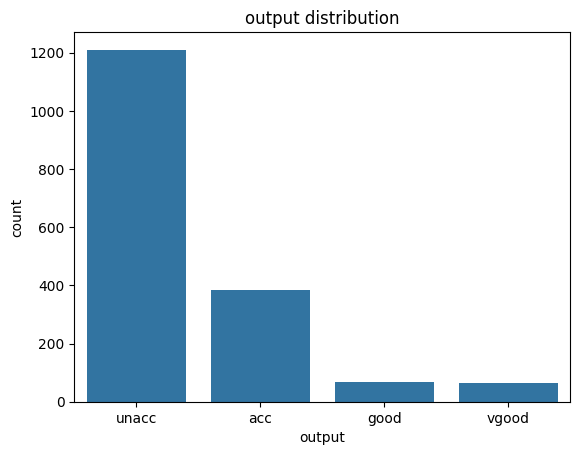

In [14]:
sns.countplot(data=df, x='output', order=['unacc', 'acc', 'good', 'vgood'])
plt.title('output distribution')   # 전부 unacc로 찍어도 정확도 70% → accuracy만으로 평가하면 위험
plt.show()

In [15]:
for col in df.columns[:-1]:
    print(f'{col:13}:', df[col].value_counts().to_dict())   # 입력 특성은 모든 값이 같은 개수 → 가능한 조합 1728개를 하나씩 다 담은 데이터

price        : {'vhigh': 432, 'high': 432, 'med': 432, 'low': 432}
maint        : {'vhigh': 432, 'high': 432, 'med': 432, 'low': 432}
doors        : {'2': 432, '3': 432, '4': 432, '5more': 432}
persons      : {'2': 576, '4': 576, 'more': 576}
lug_capacity : {'small': 576, 'med': 576, 'big': 576}
safety       : {'low': 576, 'med': 576, 'high': 576}


## 3. EDA

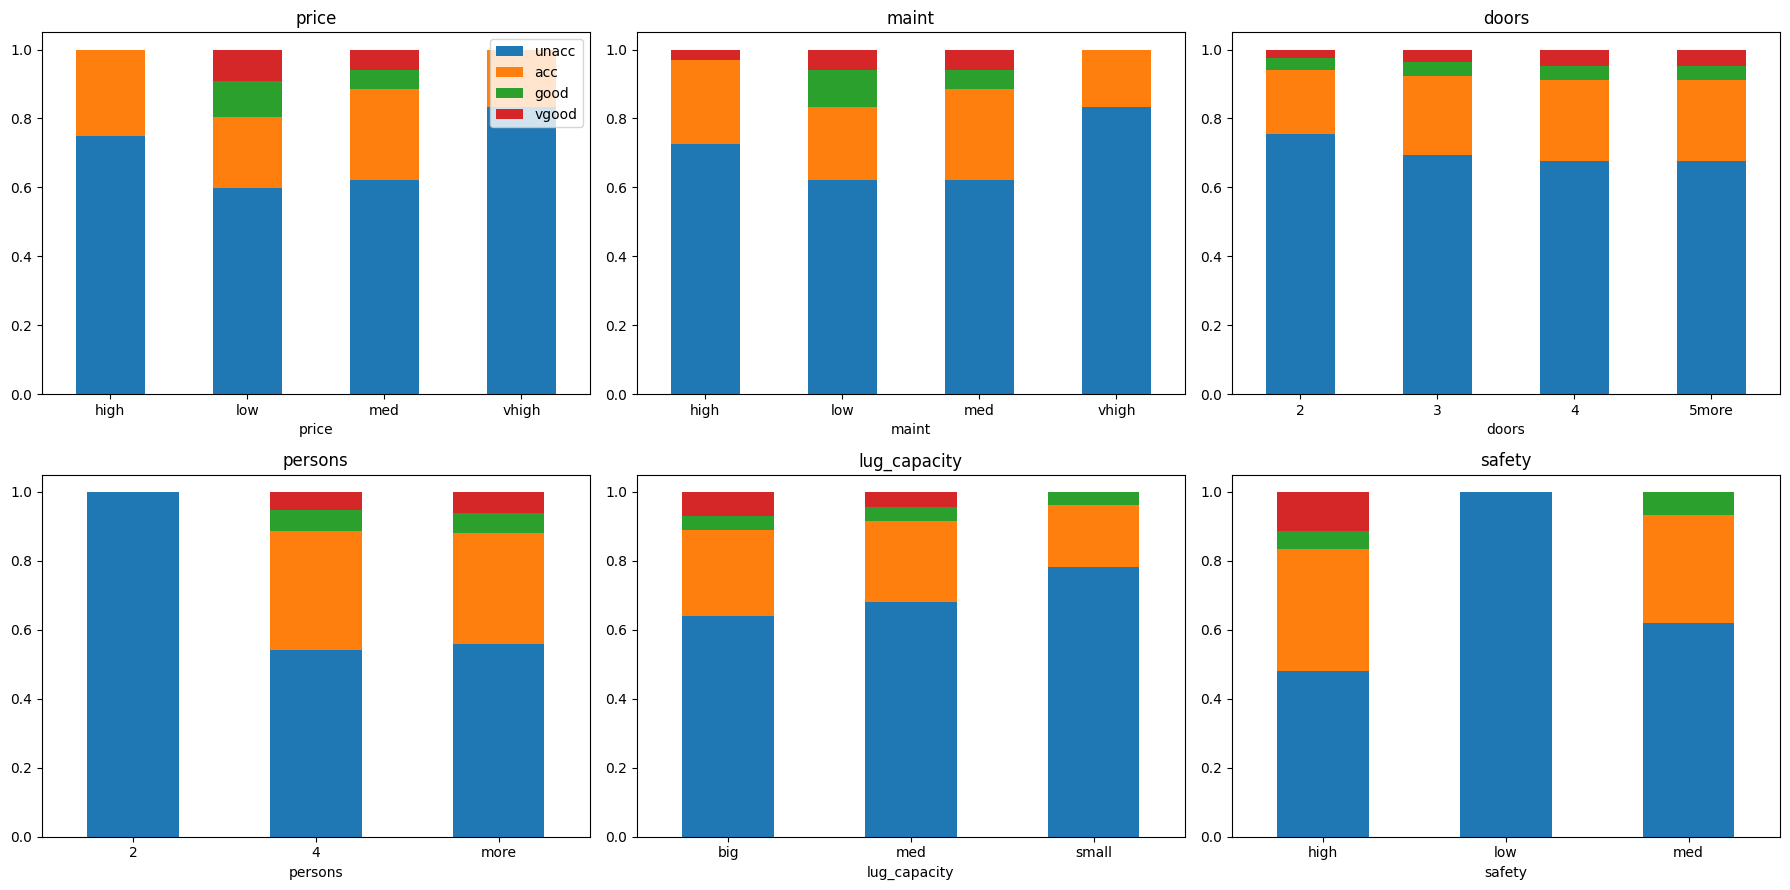

In [16]:
# 특성 값별 output 비율 → 어떤 특성이 평가를 좌우하는지 확인
order_cls = ['unacc', 'acc', 'good', 'vgood']
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), df.columns[:-1]):
    ct = pd.crosstab(df[col], df['output'], normalize='index')[order_cls]   # 행 기준 비율
    ct.plot.bar(stacked=True, ax=ax, rot=0, legend=False)
    ax.set_title(col)
axes[0, 0].legend(order_cls, loc='upper right')
plt.tight_layout()
plt.show()

In [17]:
# 규칙 확인: safety=low 또는 persons=2면 무조건 unacc
print(pd.crosstab(df['safety'], df['output'])[order_cls])    # safety=low → 576개 전부 unacc
print(pd.crosstab(df['persons'], df['output'])[order_cls])   # persons=2 → 576개 전부 unacc
# → 조건 하나로 결과가 정해지는 '규칙 기반(비선형)' 구조 → 트리·DNN 같은 비선형 모델이 유리할 것으로 예상

output  unacc  acc  good  vgood
safety                         
high      277  204    30     65
low       576    0     0      0
med       357  180    39      0
output   unacc  acc  good  vgood
persons                         
2          576    0     0      0
4          312  198    36     30
more       322  186    33     35


## 4. 인코딩 · 데이터 분할 · 스케일링

In [18]:
from sklearn.preprocessing import LabelEncoder

raw = df.copy()   # 원본 문자열 데이터 보관 (7번 원인 분석에서 사용)

columns = ['price', 'maint', 'doors', 'persons', 'lug_capacity', 'safety', 'output']
label_encoders = {}
for column in columns:
    label_encoders[column] = LabelEncoder()
    df[column] = label_encoders[column].fit_transform(df[column])   # 문자열 → 정수 (알파벳순으로 번호 부여)

class_names = list(label_encoders['output'].classes_)   # ['acc', 'good', 'unacc', 'vgood'] → 0, 1, 2, 3
print('output 번호:', dict(enumerate(class_names)))
df['output'].value_counts()   # 2(unacc)가 1210개로 가장 많음

output 번호: {0: 'acc', 1: 'good', 2: 'unacc', 3: 'vgood'}


,count
output,
2,1210
0,384
1,69
3,65


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.utils import to_categorical

X = df.drop('output', axis=1).values
y = df['output'].values

# train 60% / validation 20% / test 20%, stratify로 불균형 비율 유지 (good/vgood가 한쪽에 몰리지 않게)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y)                    # test는 마지막 최종 평가에만 사용
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=0, stratify=y_temp)    # 모델 비교·원인 분석은 validation으로

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # 분할 후 train 기준으로만 평균/표준편차 학습
X_val   = scaler.transform(X_val)         # val/test는 변환만
X_test  = scaler.transform(X_test)

y_train_oh = to_categorical(y_train, 4)   # DNN용 원-핫 라벨 (예: 2 → [0,0,1,0])
y_val_oh   = to_categorical(y_val, 4)
y_test_oh  = to_categorical(y_test, 4)

print(X_train.shape, X_val.shape, X_test.shape)   # (1036, 6) (346, 6) (346, 6)
print('train:', np.bincount(y_train))             # 불균형 비율 그대로 유지
print('val  :', np.bincount(y_val))
print('test :', np.bincount(y_test))

(1036, 6) (346, 6) (346, 6)
train: [230  41 726  39]
val  : [ 77  14 242  13]
test : [ 77  14 242  13]


In [20]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix

def cls_score(y_true, y_pred):
    return {'accuracy': round(accuracy_score(y_true, y_pred), 3),
            'macro_f1': round(f1_score(y_true, y_pred, average='macro'), 3)}   # 클래스별 F1의 단순 평균 → 소수 클래스도 똑같이 반영

# 기준선: 전부 가장 많은 클래스(unacc=2)로 예측
baseline_pred = np.full(len(y_val), 2)
print('기준선(전부 unacc) val:', cls_score(y_val, baseline_pred))
# 정확도는 0.70으로 높아 보이지만 macro F1은 0.21 → 불균형 데이터에선 macro F1을 함께 봐야 함

기준선(전부 unacc) val: {'accuracy': 0.699, 'macro_f1': 0.206}


## 5. 머신러닝 모델 (validation)

In [21]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    'SVM':           SVC(random_state=0),
    'Decision Tree': DecisionTreeClassifier(random_state=0),
    'Random Forest': RandomForestClassifier(random_state=0),
}

results = [{'model': 'Baseline (전부 unacc)', **cls_score(y_val, baseline_pred)}]
for name, clf in models.items():
    clf.fit(X_train, y_train)
    pred = clf.predict(X_val)
    results.append({'model': name, **cls_score(y_val, pred)})
    print(f'--- {name} ---')
    print(cls_score(y_val, pred))
    print(confusion_matrix(y_val, pred))   # 행: 실제, 열: 예측 (0 acc, 1 good, 2 unacc, 3 vgood)
    print()

--- SVM ---
{'accuracy': 0.89, 'macro_f1': 0.652}
[[ 68   0   9   0]
 [ 14   0   0   0]
 [ 12   0 230   0]
 [  3   0   0  10]]

--- Decision Tree ---
{'accuracy': 0.98, 'macro_f1': 0.92}
[[ 75   2   0   0]
 [  0  13   1   0]
 [  1   0 241   0]
 [  1   2   0  10]]

--- Random Forest ---
{'accuracy': 0.962, 'macro_f1': 0.892}
[[ 72   0   5   0]
 [  6   8   0   0]
 [  1   0 241   0]
 [  0   1   0  12]]



## 6. 딥러닝(DNN) 모델

In [22]:
from tensorflow.keras import layers

def build_model(hidden=(64, 32), last_activation='softmax'):
    model = keras.Sequential([layers.Input(shape=(6,))])           # 입력: 특성 6개
    for units in hidden:
        model.add(layers.Dense(units, activation='relu'))          # 은닉층
    model.add(layers.Dense(4, activation=last_activation))         # 출력층: 클래스 4개, softmax → 확률 합 1
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy',
                 keras.metrics.F1Score(average='macro', name='f1')],   # 불균형 대비 macro F1도 함께 모니터링
    )
    return model

def train_eval(model, epochs=500):
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20,    # val loss가 20 epoch 동안 안 줄면 중단
        restore_best_weights=True)          # 가장 좋았던 시점의 가중치로 복원 → 과적합 방지
    hist = model.fit(X_train, y_train_oh, validation_data=(X_val, y_val_oh),
                     epochs=epochs, batch_size=32, callbacks=[early_stop], verbose=0)
    pred = model.predict(X_val, verbose=0).argmax(axis=1)   # 확률이 가장 큰 클래스를 예측값으로
    return hist, pred

dnn = build_model()
dnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,660 (10.39 KB)

 Trainable params: 2,660 (10.39 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
history, dnn_pred = train_eval(dnn)
dnn_score = cls_score(y_val, dnn_pred)
results.append({'model': 'DNN (은닉층 2개)', **dnn_score})

print('학습 epoch 수:', len(history.history['loss']))
print('DNN val:', dnn_score)
print(confusion_matrix(y_val, dnn_pred))

학습 epoch 수: 255
DNN val: {'accuracy': 0.988, 'macro_f1': 0.96}
[[ 76   0   1   0]
 [  1  13   0   0]
 [  0   1 241   0]
 [  0   1   0  12]]


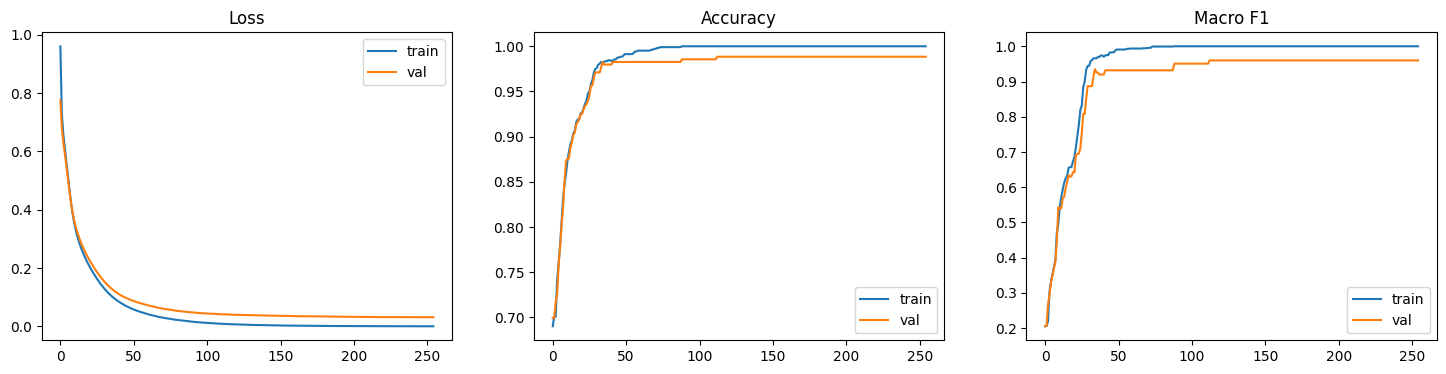

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, key, title in zip(axes, ['loss', 'accuracy', 'f1'], ['Loss', 'Accuracy', 'Macro F1']):
    ax.plot(history.history[key], label='train')
    ax.plot(history.history['val_' + key], label='val')   # val 곡선이 train과 함께 수렴 → 과적합 적음
    ax.set_title(title); ax.legend()
plt.show()

In [25]:
probs = dnn.predict(X_val, verbose=0)   # softmax 출력: 샘플별 4개 클래스 확률
print(probs[:3].round(3))               # 각 행의 합 = 1
print(probs[:3].sum(axis=1))            # argmax(가장 큰 확률)가 예측 클래스

[[0.    0.    1.    0.   ]
 [0.161 0.    0.839 0.   ]
 [0.    0.    1.    0.   ]]
[0.99999994 0.9999999  0.99999994]


In [26]:
result_df = pd.DataFrame(results).sort_values('macro_f1', ascending=False)
result_df   # SVM은 정확도에 비해 macro F1이 크게 낮음 → 7번에서 원인 분석

,model,accuracy,macro_f1
4,DNN (은닉층 2개),0.988,0.960
2,Decision Tree,0.980,0.920
3,Random Forest,0.962,0.892
1,SVM,0.890,0.652
0,Baseline (전부 unacc),0.699,0.206


## 7. 성능이 낮은 경우 원인 분석 (validation)

In [27]:
# [원인 1] 클래스 불균형: 개수가 적은 good을 아예 못 맞힘
svm = models['SVM']
print('클래스 순서:', class_names)
print('SVM recall           :', recall_score(y_val, svm.predict(X_val), average=None).round(2))   # good recall 0

svm_bal = SVC(random_state=0, class_weight='balanced')   # 개수가 적은 클래스의 오답에 더 큰 벌점
svm_bal.fit(X_train, y_train)
print('class_weight 적용 recall:', recall_score(y_val, svm_bal.predict(X_val), average=None).round(2))   # good recall 크게 상승
print('기본    :', cls_score(y_val, svm.predict(X_val)))
print('적용 후 :', cls_score(y_val, svm_bal.predict(X_val)))   # 정확도는 소폭 하락, macro F1은 상승

클래스 순서: ['acc', 'good', 'unacc', 'vgood']
SVM recall           : [0.88 0.   0.95 0.77]
class_weight 적용 recall: [0.83 1.   0.87 1.  ]
기본    : {'accuracy': 0.89, 'macro_f1': 0.652}
적용 후 : {'accuracy': 0.873, 'macro_f1': 0.824}


In [28]:
# [원인 2] LabelEncoder의 알파벳순 번호: 크기 순서가 섞임
print('price :', dict(enumerate(label_encoders['price'].classes_)))    # high=0, low=1, med=2, vhigh=3 → 순서 엉망
print('safety:', dict(enumerate(label_encoders['safety'].classes_)))   # high=0, low=1, med=2

# 순서형(ordinal) 인코딩: 실제 크기 순서대로 0, 1, 2, 3 부여
order = {
    'price':        ['low', 'med', 'high', 'vhigh'],
    'maint':        ['low', 'med', 'high', 'vhigh'],
    'doors':        ['2', '3', '4', '5more'],
    'persons':      ['2', '4', 'more'],
    'lug_capacity': ['small', 'med', 'big'],
    'safety':       ['low', 'med', 'high'],
}
X_ord = raw.drop(columns='output').astype(str)
for col, values in order.items():
    X_ord[col] = X_ord[col].map({v: i for i, v in enumerate(values)})
X_ord = X_ord.values

# 같은 random_state·stratify로 나눠 위와 똑같은 행 구성 유지
Xo_temp, Xo_test, _, _ = train_test_split(X_ord, y, test_size=0.2, random_state=0, stratify=y)
Xo_train, Xo_val, _, _ = train_test_split(Xo_temp, y_temp, test_size=0.25, random_state=0, stratify=y_temp)
sc_o = StandardScaler()
Xo_train, Xo_val = sc_o.fit_transform(Xo_train), sc_o.transform(Xo_val)

svm_ord = SVC(random_state=0).fit(Xo_train, y_train)
print('LabelEncoder(알파벳순):', cls_score(y_val, svm.predict(X_val)))
print('순서형 인코딩        :', cls_score(y_val, svm_ord.predict(Xo_val)))   # macro F1 크게 상승

price : {0: 'high', 1: 'low', 2: 'med', 3: 'vhigh'}
safety: {0: 'high', 1: 'low', 2: 'med'}
LabelEncoder(알파벳순): {'accuracy': 0.89, 'macro_f1': 0.652}
순서형 인코딩        : {'accuracy': 0.96, 'macro_f1': 0.882}


In [29]:
# [원인 3] 모델이 너무 단순: 'safety=low면 무조건 unacc' 같은 규칙(비선형)을 직선 경계로 표현 못 함
tf.keras.utils.set_random_seed(0)
_, simple_pred = train_eval(build_model(hidden=()))   # 은닉층 없음 = 로지스틱 회귀와 같은 선형 구조
print('은닉층 없는 DNN:', cls_score(y_val, simple_pred))   # 낮음
print('은닉층 2개 DNN :', dnn_score)                      # 은닉층이 비선형 규칙을 학습

은닉층 없는 DNN: {'accuracy': 0.699, 'macro_f1': 0.364}
은닉층 2개 DNN : {'accuracy': 0.988, 'macro_f1': 0.96}


In [30]:
# [원인 4] 출력층 activation: softmax의 필요성을 확인하기 위한 대조 실험
# relu는 음수를 0으로 잘라 출력이 확률 분포가 되지 않음
tf.keras.utils.set_random_seed(0)
_, relu_pred = train_eval(build_model(last_activation='relu'))
print('출력층 relu   :', cls_score(y_val, relu_pred))   # 정확도는 그럴듯해도 macro F1 낮음
print('출력층 softmax:', dnn_score)
print('relu 예측 클래스 종류:', np.unique(relu_pred))     # 일부 클래스만 예측

출력층 relu   : {'accuracy': 0.76, 'macro_f1': 0.334}
출력층 softmax: {'accuracy': 0.988, 'macro_f1': 0.96}
relu 예측 클래스 종류: [0 2]


## 8. 최종 평가 (test)

In [31]:
# validation 기준 macro F1이 가장 높은 모델을 최종 선택 → test는 여기서 한 번만 사용
final_name = result_df.iloc[0]['model']
print('최종 모델:', final_name)

if final_name.startswith('DNN'):
    test_pred = dnn.predict(X_test, verbose=0).argmax(axis=1)
else:
    test_pred = models[final_name].predict(X_test)
print('최종 모델 test:', cls_score(y_test, test_pred))

최종 모델: DNN (은닉층 2개)
최종 모델 test: {'accuracy': 0.971, 'macro_f1': 0.944}


In [32]:
from sklearn.metrics import classification_report

print(classification_report(y_test, test_pred, target_names=class_names))   # 소수 클래스(good, vgood) 성능까지 확인

              precision    recall  f1-score   support

         acc       0.96      0.92      0.94        77
        good       1.00      0.93      0.96        14
       unacc       0.98      0.99      0.99       242
       vgood       0.86      0.92      0.89        13

    accuracy                           0.97       346
   macro avg       0.95      0.94      0.94       346
weighted avg       0.97      0.97      0.97       346



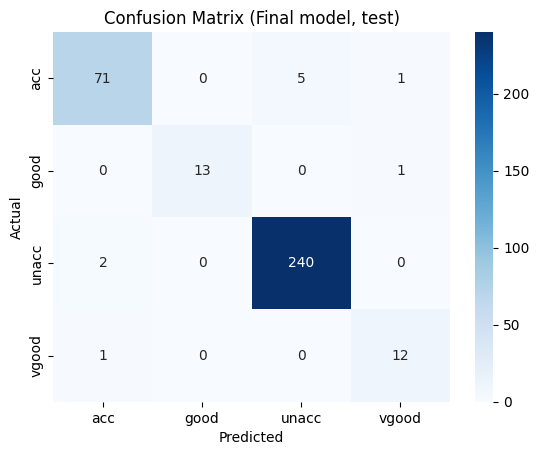

In [33]:
cm = confusion_matrix(y_test, test_pred)   # 행: 실제, 열: 예측
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual')   # 오답은 주로 인접 등급(acc↔good 등) 사이
plt.title('Confusion Matrix (Final model, test)')
plt.show()

## 9. 결과 정리

**평가 방식**
- 데이터를 train 60% / validation 20% / test 20%로 나눴다.
- 모델 비교와 원인 분석은 validation으로 했고, test는 최종 모델 평가에 **한 번만** 사용했다.

**모델별 Validation 결과**

| 모델 | Accuracy | Macro F1 |
|---|---|---|
| DNN (은닉층 2개) | **0.988** | **0.960** |
| Decision Tree | 0.980 | 0.920 |
| Random Forest | 0.962 | 0.892 |
| SVM | 0.890 | 0.652 |
| Baseline (전부 unacc) | 0.699 | 0.206 |

- SVM은 정확도 0.89로 괜찮아 보이지만 macro F1이 0.65로 크게 낮았다. 혼동행렬을 보면 **good 14개를 하나도 맞히지 못했다.**

**5. 성능이 낮은 경우 원인 분석 (validation 기준)**

| 원인 | 실험 | Macro F1 |
|---|---|---|
| ① 클래스 불균형 | SVM 기본 → class_weight='balanced' | 0.652 → **0.824** |
| ② LabelEncoder의 알파벳순 번호 | SVM LabelEncoder → 순서형 인코딩 | 0.652 → **0.882** |
| ③ 모델이 너무 단순 | DNN 은닉층 없음 → 2개 | 0.364 → **0.960** |
| ④ 출력층 activation (대조 실험) | 출력층 relu → softmax | 0.334 → **0.960** |

- ① good은 train에 41개뿐이라 SVM이 사실상 무시했다(recall 0). class_weight로 소수 클래스의 오답에 더 큰 벌점을 주자 good recall이 1.00이 되었다. 대신 정확도는 0.89에서 0.87로 소폭 내려가, 소수 클래스를 챙기면 다수 클래스에서 약간 손해 보는 trade-off가 있었다.
- ② LabelEncoder는 알파벳순으로 번호를 매겨 price가 high=0, low=1, med=2, vhigh=3이 되는 등 크기 순서가 뒤섞인다. SVM처럼 거리를 계산하는 모델은 이 순서에 영향을 받는다. 실제 순서대로(low=0 < med=1 < high=2 < vhigh=3) 인코딩하자 macro F1이 크게 올랐다.
- ③ 은닉층이 없는 모델은 로지스틱 회귀와 같은 선형 구조라 "safety=low면 무조건 unacc" 같은 규칙을 표현하지 못해, 기준선과 거의 같은 수준(정확도 0.70)에 머물렀다. 은닉층을 추가하자 비선형 규칙을 학습했다.
- ④ 출력층에 relu를 쓰면 출력이 확률 분포가 되지 않아 acc와 unacc 두 클래스만 예측했다. 정확도는 0.76으로 그럴듯해 보여도 macro F1은 0.33으로, 다중 분류 출력층에는 softmax가 필요함을 확인했다.

**최종 결과 (test)**
- validation macro F1이 가장 높았던 **DNN(은닉층 2개)** 을 최종 모델로 선택했다.
- test 정확도 **0.971**, macro F1 **0.944**로 validation과 비슷해 일반화가 잘 되었다.
- 소수 클래스인 good(recall 0.93)과 vgood(recall 0.92)도 잘 맞혔고, 오답은 주로 인접 등급 사이에서 발생했다.

**느낀 점**
- 불균형 데이터에서는 정확도가 높아도 소수 클래스를 전혀 못 맞힐 수 있어서, macro F1과 혼동행렬을 함께 봐야 한다는 것을 배웠다.
- LabelEncoder처럼 편하게 쓰던 인코딩도 데이터의 순서 의미를 망가뜨릴 수 있고, 모델 종류에 따라 영향이 다르다는 점을 확인했다.
- EDA에서 발견한 규칙 기반 구조가 "선형 모델은 약하고 비선형 모델은 강하다"는 결과로 그대로 이어지는 것을 볼 수 있었다.
- 성능이 낮을 때 조건을 하나씩 바꾸는 실험으로 원인을 직접 확인할 수 있었다.